In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn import metrics

In [2]:
df = pd.read_csv("cyber_threats_dataset.csv")
df = df.dropna()

In [3]:
encoder = LabelEncoder()
df["Protocol"] = encoder.fit_transform(df["Protocol"])
df["Packet"] = encoder.fit_transform(df["Packet"])
df["Target Variable"] = encoder.fit_transform(df["Target Variable"])

In [4]:
features = ["Protocol", "Packet", "Source Port", "Destination Port", "Packet Size"]
X = df[features]

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [7]:
dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [8]:
agglo = AgglomerativeClustering(n_clusters=4)
agglo_labels = agglo.fit_predict(X_scaled)

In [9]:
rand_kmeans = metrics.rand_score(kmeans_labels, agglo_labels)
rand_dbscan = metrics.rand_score(dbscan_labels, agglo_labels)

mutual_info_kmeans = metrics.adjusted_mutual_info_score(kmeans_labels, agglo_labels)
mutual_info_dbscan = metrics.adjusted_mutual_info_score(dbscan_labels, agglo_labels)

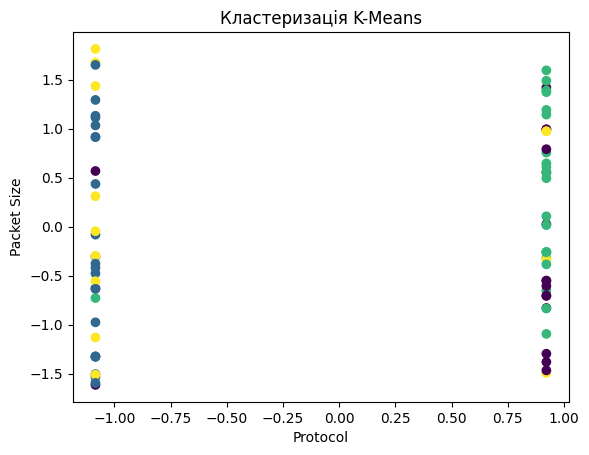

In [10]:
plt.scatter(X_scaled[:, 0], X_scaled[:, 4], c=kmeans_labels, cmap="viridis")
plt.title("Кластеризація K-Means")
plt.xlabel(features[0])
plt.ylabel(features[4])
plt.show()

In [11]:
print(f"Метрика Rand Score (K-Means vs Agglomerative): {rand_kmeans:.3f}")
print(f"Метрика Mutual Info (K-Means vs Agglomerative): {mutual_info_kmeans:.3f}")
print(f"Метрика Rand Score (DBSCAN vs Agglomerative): {rand_dbscan:.3f}")
print(f"Метрика Mutual Info (DBSCAN vs Agglomerative): {mutual_info_dbscan:.3f}")

best_method = "K-Means" if rand_kmeans > rand_dbscan else "DBSCAN"
print(f"Найкращий метод кластеризації: {best_method}")
print(f"Параметри: {'n_clusters=4' if best_method == 'K-Means' else 'eps=1.5, min_samples=5'}")

Метрика Rand Score (K-Means vs Agglomerative): 0.889
Метрика Mutual Info (K-Means vs Agglomerative): 0.696
Метрика Rand Score (DBSCAN vs Agglomerative): 0.836
Метрика Mutual Info (DBSCAN vs Agglomerative): 0.673
Найкращий метод кластеризації: K-Means
Параметри: n_clusters=4
